In [6]:
import h5py as h
import numpy as np
import pandas as pd

data_path = (
    "/Users/icarus/Desktop/SPODcode/spod_matlab/spod_complete_continuous_database.mat"
)

# 1. DEFINE TARGETS FOR THE 3-MODE CASADE
target_st_list = [0.1, 0.4, 0.8]
mode_idx = 0  # Dominant Mode 0 for all

# Arrays to hold individual mode series
a_modes = []
dz_dt_analytic_modes = []

print("=" * 60)
print("EXTRACTING AND PROCESSING CONTINOUS COEFFICIENTS")
print("=" * 60)

with h.File(data_path, "r") as file:
    st_vector = np.squeeze(file["St_vector"][:])
    t_uniform = np.squeeze(file["t_uniform"][:])
    dt = t_uniform[1] - t_uniform[0]

    for target_st in target_st_list:
        target_fi = int(np.argmin(np.abs(st_vector - target_st)))
        actual_st = st_vector[target_fi]
        print(
            f"Target St: {target_st} -> Extracted St: {actual_st:.4f} (Python Index {target_fi})"
        )

        # Pull complex components
        a_real = file["A_coeffs_continuous_real"][:, mode_idx, target_fi]
        a_imag = file["A_coeffs_continuous_imag"][:, mode_idx, target_fi]
        a_complex = (a_real + 1j * a_imag).flatten()

        a_modes.append(a_complex)

        # Compute clean analytical derivatives using phase velocity tracking
        r_true = np.abs(a_complex)
        phase_true = np.unwrap(np.angle(a_complex))

        dr_dt = np.gradient(r_true, dt)
        omega = np.gradient(phase_true, dt)

        # Complete complex vector velocity tracking
        da_dt_analytic = (dr_dt + 1j * r_true * omega) * np.exp(1j * phase_true)
        dz_dt_analytic_modes.append(da_dt_analytic)

# 2. TRAIN / VAL / TEST SPLITS (Index 2700 / 3000)
train_end_idx = 2700
val_end_idx = 3000

# Stack states horizontally over modes, then slice for train [time_steps x 3]
Q_raw = np.column_stack(a_modes)
dQ_dt_raw = np.column_stack(dz_dt_analytic_modes)

Q_train = Q_raw[:train_end_idx, :]  # Shape: (2700, 3)
dQ_dt_train = dQ_dt_raw[:train_end_idx, :]  # Shape: (2700, 3)

Q_val = Q_raw[train_end_idx:val_end_idx, :]
Q_test = Q_raw[val_end_idx:, :]

print("\n" + "=" * 60)
print(f"Unified Train State Matrix Q shape: {Q_train.shape}")
print(f"Unified Train Derivative Matrix dQ/dt shape: {dQ_dt_train.shape}")
print("=" * 60)


# 3. BUILD THE GLOBAL UNIFIED LIBRARY (Linear + Kronecker Quadratic)
# Compute Kronecker product row by row over time steps for Q⊗Q
num_train_steps = Q_train.shape[0]
Q_kron_Q_list = []

for i in range(num_train_steps):
    # np.kron on length-3 vectors yields a length-9 vector of cross-interactions
    Q_kron_Q_list.append(np.kron(Q_train[i, :], Q_train[i, :]))

Q_kron_Q_train = np.array(Q_kron_Q_list)  # Shape: (2700, 9)

# Construct unified library matrix: [ Q , Q⊗Q ] -> Shape: (2700, 12)
Theta_global = np.column_stack([Q_train, Q_kron_Q_train])


# 4. SIMULTANEOUS MATRIX MULTI-VARIABLE REGRESSION
# Solving: Theta_global @ [A_global, B_global].T = dQ_dt_train
Xi_global, residuals, rank, s = np.linalg.lstsq(
    Theta_global, dQ_dt_train, rcond=None
)

# Transpose back to align with standard differential form: dQ/dt = A@Q + B@(Q⊗Q)
Operators = Xi_global.T  # Shape: (3, 12)

A_global = Operators[:, :3]  # Linear Coefficients Matrix (3x3)
B_global = Operators[:, 3:]  # Quadratic Coupling Tensor Matrix (3x9)

# 5. DISPLAY UNIFIED RESULTS
print("\n" + "=" * 60)
print("DISCOVERED UNIFIED STATE OPERATORS")
print("=" * 60)

print("\n--- GLOBAL LINEAR MATRIX A (3x3) ---")
for i in range(3):
    row_str = " | ".join(
        [f"{val.real:+.4e} {val.imag:+.4e}j" for val in A_global[i, :]]
    )
    print(f"Mode {i} Eq: {row_str}")

print("\n--- GLOBAL QUADRATIC COUPLING TENSOR B (3x9) ---")
# Column reference mapping for your records:
# [q1q1, q1q2, q1q3, q2q1, q2q2, q2q3, q3q1, q3q2, q3q3]
for i in range(3):
    print(f"\nMode {i} Equation Triadic Forcing Coefficients:")
    print(
        f"  Self St_0.1 (q1^2):    {B_global[i, 0].real:+.4e} {B_global[i, 0].imag:+.4e}j"
    )
    print(
        f"  Cross St_0.1-0.4:      {B_global[i, 1].real:+.4e} {B_global[i, 1].imag:+.4e}j"
    )
    print(
        f"  Cross St_0.1-0.8:      {B_global[i, 2].real:+.4e} {B_global[i, 2].imag:+.4e}j"
    )
    print(
        f"  Self St_0.4 (q2^2):    {B_global[i, 4].real:+.4e} {B_global[i, 4].imag:+.4e}j"
    )
    print(
        f"  Cross St_0.4-0.8:      {B_global[i, 5].real:+.4e} {B_global[i, 5].imag:+.4e}j"
    )
    print(
        f"  Self St_0.8 (q3^2):    {B_global[i, 8].real:+.4e} {B_global[i, 8].imag:+.4e}j"
    )
print("=" * 60)

EXTRACTING AND PROCESSING CONTINOUS COEFFICIENTS
Target St: 0.1 -> Extracted St: 0.0854 (Python Index 2)
Target St: 0.4 -> Extracted St: 0.3842 (Python Index 9)
Target St: 0.8 -> Extracted St: 0.8112 (Python Index 19)

Unified Train State Matrix Q shape: (2700, 3)
Unified Train Derivative Matrix dQ/dt shape: (2700, 3)

DISCOVERED UNIFIED STATE OPERATORS

--- GLOBAL LINEAR MATRIX A (3x3) ---
Mode 0 Eq: -2.5715e+01 +1.0081e+04j | -2.1192e+00 -4.9151e+00j | -9.5750e+00 +4.6120e+00j
Mode 1 Eq: -3.8462e-01 +1.3191e+00j | +1.1732e+01 +4.2846e+04j | -4.9033e+00 +1.3898e+01j
Mode 2 Eq: -2.2878e-02 +1.1470e-01j | -9.7012e-01 -3.8962e-01j | -1.3019e+02 +9.0926e+04j

--- GLOBAL QUADRATIC COUPLING TENSOR B (3x9) ---

Mode 0 Equation Triadic Forcing Coefficients:
  Self St_0.1 (q1^2):    -1.5480e-01 -5.6304e-02j
  Cross St_0.1-0.4:      +1.1465e+06 +5.9446e+05j
  Cross St_0.1-0.8:      +2.1734e+06 +8.4503e+04j
  Self St_0.4 (q2^2):    -3.2025e-04 -2.6267e-03j
  Cross St_0.4-0.8:      +3.7656e+04 -1

In [7]:
# ==============================================================================
# UNIFIED METRICS EVALUATION BLOCK (3 FREQUENCIES)
# ==============================================================================

# ---- 1. TRAIN SET FIT EVALUATION ----
# Reconstruct the Kronecker product Q⊗Q over time for training data
Q_kron_Q_train_list = [np.kron(Q_train[i, :], Q_train[i, :]) for i in range(Q_train.shape[0])]
Q_kron_Q_train_mat = np.array(Q_kron_Q_train_list)

# Unified model prediction: dQ/dt = A@Q + B@(Q⊗Q)
# Transpose operations ensure correct broadcast over time steps (2700, 3)
dQ_dt_pred_train = (A_global @ Q_train.T + B_global @ Q_kron_Q_train_mat.T).T

print("="*60)
print("TRAINING SET PERFORMANCE LOG")
print("="*60)

# Track metrics per individual frequency channel
freq_labels = ["St=0.0854", "St=0.3842", "St=0.8112"]
for i, label in enumerate(freq_labels):
    true_chan = dQ_dt_train[:, i]
    pred_chan = dQ_dt_pred_train[:, i]
    res_chan  = true_chan - pred_chan
    
    rel_err_chan = np.linalg.norm(res_chan) / np.linalg.norm(true_chan)
    r2_chan = 1 - (np.sum(np.abs(res_chan)**2) / np.sum(np.abs(true_chan - np.mean(true_chan))**2))
    print(f"[{label}] Rel Error: {rel_err_chan * 100:6.2f}% | R² Score: {r2_chan * 100:6.2f}%")

# Global Multi-Variable Metric across all 3 channels combined
res_train_global = dQ_dt_train - dQ_dt_pred_train
rel_err_train_global = np.linalg.norm(res_train_global) / np.linalg.norm(dQ_dt_train)
r2_train_global = 1 - (np.sum(np.abs(res_train_global)**2) / np.sum(np.abs(dQ_dt_train - np.mean(dQ_dt_train, axis=0))**2))
print(f"--> GLOBAL MULTI-VAR  | Rel Error: {rel_err_train_global * 100:6.2f}% | R² Score: {r2_train_global * 100:6.2f}%")


# ---- 2. TEST SET FIT EVALUATION ----
# Reconstruct the Kronecker product Q⊗Q over time for test data
# Note: slicing Q_raw and dQ_dt_raw past the val index to match your test boundary
Q_test = Q_raw[val_end_idx:, :]
dQ_dt_test = dQ_dt_raw[val_end_idx:, :]

Q_kron_Q_test_list = [np.kron(Q_test[i, :], Q_test[i, :]) for i in range(Q_test.shape[0])]
Q_kron_Q_test_mat = np.array(Q_kron_Q_test_list)

# Unified model prediction on unseen test intervals
dQ_dt_pred_test = (A_global @ Q_test.T + B_global @ Q_kron_Q_test_mat.T).T

print("\n" + "="*60)
print("TEST SET PERFORMANCE LOG (UNSEEN TRAJECTORIES)")
print("="*60)

# Track metrics per individual frequency channel
for i, label in enumerate(freq_labels):
    true_chan = dQ_dt_test[:, i]
    pred_chan = dQ_dt_pred_test[:, i]
    res_chan  = true_chan - pred_chan
    
    rel_err_chan = np.linalg.norm(res_chan) / np.linalg.norm(true_chan)
    r2_chan = 1 - (np.sum(np.abs(res_chan)**2) / np.sum(np.abs(true_chan - np.mean(true_chan))**2))
    print(f"[{label}] Rel Error: {rel_err_chan * 100:6.2f}% | R² Score: {r2_chan * 100:6.2f}%")

# Global Multi-Variable Metric across all 3 test channels combined
res_test_global = dQ_dt_test - dQ_dt_pred_test
rel_err_test_global = np.linalg.norm(res_test_global) / np.linalg.norm(dQ_dt_test)
r2_test_global = 1 - (np.sum(np.abs(res_test_global)**2) / np.sum(np.abs(dQ_dt_test - np.mean(dQ_dt_test, axis=0))**2))
print(f"--> GLOBAL MULTI-VAR  | Rel Error: {rel_err_test_global * 100:6.2f}% | R² Score: {r2_test_global * 100:6.2f}%")

TRAINING SET PERFORMANCE LOG
[St=0.0854] Rel Error:  23.21% | R² Score:  94.61%
[St=0.3842] Rel Error:   6.24% | R² Score:  99.61%
[St=0.8112] Rel Error:   3.19% | R² Score:  99.90%
--> GLOBAL MULTI-VAR  | Rel Error:   6.71% | R² Score:  99.55%

TEST SET PERFORMANCE LOG (UNSEEN TRAJECTORIES)
[St=0.0854] Rel Error:  23.08% | R² Score:  94.67%
[St=0.3842] Rel Error:   6.59% | R² Score:  99.57%
[St=0.8112] Rel Error:   3.35% | R² Score:  99.89%
--> GLOBAL MULTI-VAR  | Rel Error:   7.17% | R² Score:  99.49%


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchdiffeq import odeint_adjoint as odeint

# ==============================================================================
# 1. UNIFIED 3-FREQUENCY VECTOR FIELD WITH DYNAMIC BATCH HANDLING
# ==============================================================================
class ODEField(nn.Module):
    def __init__(self, A_tensor, B_tensor):
        super().__init__()
        # A_tensor shape: [3, 3] (Linear Matrix)
        # B_tensor shape: [3, 9] (Quadratic Coupling Tensor)
        self.A_tensor = A_tensor
        self.B_tensor = B_tensor

    def forward(self, t, z):
        # Handle unbatched 1D evaluation inputs (e.g., from global odeint tracking) smoothly
        is_unbatched = (z.dim() == 1)
        if is_unbatched:
            z = z.unsqueeze(0)  # Shape: [3] -> [1, 3]
        
        # Compute Linear Term: A @ Q -> Shape: [Batch, 3]
        linear_term = torch.einsum('ij,bj->bi', self.A_tensor, z)
        
        # Compute Vectorized Kronecker Product: Q ⊗ Q -> Shape: [Batch, 9]
        # Evaluates all cross-frequency interactions [q1^2, q1q2, q1q3, ..., q3^2]
        z_kron_z = torch.einsum('bi,bj->bij', z, z).flatten(start_dim=1)
        
        # Compute Quadratic Interaction Term: B @ (Q ⊗ Q) -> Shape: [Batch, 3]
        quadratic_term = torch.einsum('ij,bj->bi', self.B_tensor, z_kron_z)
        
        # Unified System Equation: dQ/dt = A@Q + B@(Q⊗Q)
        dz_dt = linear_term + quadratic_term
        
        if is_unbatched:
            dz_dt = dz_dt.squeeze(0)  # Strip batch dimension back off if it came in unbatched
            
        return dz_dt


# ==============================================================================
# 2. CHANNEL-ALIGNED SPECTRAL CONVOLUTION OPERATOR 
# ==============================================================================
class UnifiedSpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes, pad_size=32):
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.modes        = modes
        self.pad_size     = pad_size  

        scale = (1.0 / (in_channels * out_channels)) ** 0.5
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, self.modes, dtype=torch.complex128)
        )

    def forward(self, q_state):
        batch_size = q_state.shape[0]
        
        # Local normalization across the incoming hidden channels
        eps = 1e-8
        mean = q_state.mean(dim=-1, keepdim=True)
        std = q_state.std(dim=-1, keepdim=True) + eps
        q_norm = (q_state - mean) / std
        
        # Smooth spatial padding for periodic boundary zone protection
        q_padded = F.pad(q_norm, (self.pad_size, self.pad_size), mode='reflect')
        padded_len = q_padded.size(-1)

        # Compute RFFT onto the padded domain
        q_ft = torch.fft.rfft(q_padded, norm="ortho")

        out_ft = torch.zeros(
            batch_size, self.out_channels, padded_len // 2 + 1, 
            device=q_padded.device, dtype=torch.complex128 
        )

        # Apply weights in frequency space to mix features across internal state dimensions
        out_ft[:, :, :self.modes] = torch.einsum(
            "bix,iox->box", 
            q_ft[:, :, :self.modes], 
            self.weights
        )

        # Transform back to physical space (padded length)
        output_padded = torch.fft.irfft(out_ft, n=padded_len, norm="ortho")
        output_norm = output_padded[..., self.pad_size : -self.pad_size]

        # Coalesce scale dimensions down to match the output channels perfectly
        out_mean = mean.mean(dim=1, keepdim=True).expand(-1, self.out_channels, -1)
        out_std  = std.mean(dim=1, keepdim=True).expand(-1, self.out_channels, -1)

        return (output_norm * out_std) + out_mean


# ==============================================================================
# 3. GLOBAL HYBRID FNO-ODE DEEP LEARNING MODEL
# ==============================================================================
class FNO1d(nn.Module):
    def __init__(self, A_global, B_global, dt, steps=64, modes=16, width=64, num_layers=3):
        super().__init__()
        self.dt = dt
        self.steps = steps
        self.modes = modes
        self.width = width

        # Register discovered global matrices as trainable parameters
        self.A_tensor = nn.Parameter(torch.tensor(A_global, dtype=torch.complex128))
        self.B_tensor = nn.Parameter(torch.tensor(B_global, dtype=torch.complex128))

        # Initialize the unified system field
        self.vector_field = ODEField(self.A_tensor, self.B_tensor)

        # Lift multi-frequency coordinate states up to feature width representation
        # 4 channels = 3 (frequencies) + 1 (timeline coordinate grid)
        self.lift = nn.Sequential(
            nn.Linear(4, self.width),
            nn.GELU(),
            nn.Linear(self.width, self.width)
        )
        
        self.lift_ode = nn.Sequential(
            nn.Linear(4, self.width),
            nn.GELU(),
            nn.Linear(self.width, self.width)
        )

        # Dual-branch mixing layers configured to feed into channel-aligned operators
        self.spectral_layers = nn.ModuleList([
            UnifiedSpectralConv1d(self.width * 2, self.width, self.modes) for _ in range(num_layers)
        ])
        
        self.skip_layers_hist = nn.ModuleList([nn.Conv1d(self.width, self.width, 1) for _ in range(num_layers)])
        self.skip_layers_ode  = nn.ModuleList([nn.Conv1d(self.width, self.width, 1) for _ in range(num_layers)])
        self.norm_layers      = nn.ModuleList([nn.InstanceNorm1d(self.width, affine=True) for _ in range(num_layers)])

        # Output multi-channel prediction heads (Outputs 3 complex channels -> 6 real channels)
        self.fc1 = nn.Conv1d(self.width, 128, kernel_size=1)
        self.fc2 = nn.Conv1d(128, 6, kernel_size=1)  # 3 Means + 3 Standard Deviations

        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.zeros_(self.fc1.bias)
        nn.init.xavier_uniform_(self.fc2.weight) 
        self.dropout = nn.Dropout(p=0.2)

    def add_temporal_grid(self, x):
        batch_size, seq_len, _ = x.shape
        grid_hist = torch.linspace(-1.0, 0.0, steps=seq_len, dtype=x.dtype, device=x.device)
        grid_hist = grid_hist.view(1, seq_len, 1).expand(batch_size, -1, -1)
        return torch.cat((x, grid_hist), dim=-1)
    
    def add_temporal_grid_ode(self, x):
        batch_size, seq_len, _ = x.shape
        grid_ode = torch.linspace(0.0, 1.0, steps=seq_len, dtype=x.dtype, device=x.device)
        grid_ode = grid_ode.view(1, seq_len, 1).expand(batch_size, -1, -1)
        return torch.cat((x, grid_ode), dim=-1)

    def forward(self, x):
        # x input shape: [Batch, 3, seq_len] (Complex input states for 3 frequencies)
        
        # ─── PATH A: UNIFIED CONTINUOUS MATRIX INTEGRATION ────────────
        # Extract boundary state at the trailing historical edge (t=0)
        z_init = x[:, :, -1]  # Shape: [Batch, 3] (Complex)

        t_steps = torch.linspace(
            self.dt, 
            self.steps * self.dt, 
            steps=self.steps, 
            dtype=torch.float64, 
            device=x.device       
        )

        # Integrate all 3 frequency trajectories simultaneously
        # Result shape from odeint: [64, Batch, 3]
        stacked_ode_complex = odeint(
            self.vector_field, 
            z_init, 
            t_steps,
            method='rk4', 
            options={'step_size': self.dt}
        )

        # Re-align shapes to physical expectations: [Batch, 3, 64]
        stacked_ode = stacked_ode_complex.permute(1, 2, 0) 
        
        # Extract real fields for coordinate mappings
        ode_out_real = stacked_ode.real.to(self.lift[0].weight.dtype)
        
        # ─── PATH B: SPECTRAL MIXING & TRUNCATION ALIGNMENT ───────────
        # Permute to sequence format for coordinate projections: [Batch, 64, 3]
        x_perm = x.real.permute(0, 2, 1).to(self.lift[0].weight.dtype)
        ode_perm = ode_out_real.permute(0, 2, 1)

        # Inject grid coordinate timeline trackers
        x_with_grids = self.add_temporal_grid(x_perm)
        ode_with_grids = self.add_temporal_grid_ode(ode_perm)
        
        h_hist = self.lift(x_with_grids).permute(0, 2, 1)      # [B, width, 64]
        h_ode = self.lift_ode(ode_with_grids).permute(0, 2, 1) # [B, width, 64]
        
        for spec, skip_h, skip_o, norm in zip(self.spectral_layers, self.skip_layers_hist, self.skip_layers_ode, self.norm_layers):
            # Combined tensor feeds into the 3-channel operator mixer
            spectral_features = spec(torch.cat([h_hist, h_ode], dim=1))
            
            h_combined = F.gelu(norm(spectral_features + skip_h(h_hist) + skip_o(h_ode)))
            h_hist = h_hist + h_combined
            h_ode  = h_ode + h_combined

        # Pointwise Projection Head
        h_combined = self.dropout(h_combined.contiguous())
        h_latent = F.gelu(self.fc1(h_combined))  # [B, 128, 64]
        stats = self.fc2(h_latent)               # [B, 6, 64]

        # Extract channel-specific predictive statistics
        # Means: stats[:, 0:3, :] | Standard Deviations: stats[:, 3:6, :]
        pred_mean = stats[:, :3, :]
        pred_std  = F.softplus(stats[:, 3:, :]) + 1e-2

        return stacked_ode, pred_mean, pred_std

In [9]:
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np

class UnifiedJetTrajectoryDataset(Dataset):
    def __init__(self, complex_modes_list, history_len=64, pred_len=64, stride=1):
        """
        complex_modes_list: List of 1D NumPy arrays, one for each St frequency.
                            Example: [a_1_complex, a_2_complex, a_3_complex]
        """
        self.history_len = history_len
        self.pred_len = pred_len
        total_window = history_len + pred_len
        
        # Stack into shape: [3, Total_Time_Steps] with type complex128 for precision tracking
        self.data = np.vstack([np.atleast_2d(mode) for mode in complex_modes_list]).astype(np.complex128)
        
        # Calculate valid window starting steps across the shared time series
        self.indices = list(range(0, self.data.shape[1] - total_window + 1, stride))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        start_idx = self.indices[idx]
        mid_idx = start_idx + self.history_len
        end_idx = mid_idx + self.pred_len
        
        # Slice the multi-frequency continuous sequences
        X = self.data[:, start_idx:mid_idx]  # Shape: [3, 64] (Complex)
        Y = self.data[:, mid_idx:end_idx]    # Shape: [3, 64] (Complex)
        
        return torch.tensor(X, dtype=torch.complex128), torch.tensor(Y, dtype=torch.complex128)

# ---- INITIALIZE THE UNIFIED LOADERS ----
# a_modes contains the full multi-frequency arrays extracted in the first block
a_modes_train = [mode[:train_end_idx] for mode in a_modes]
a_modes_val   = [mode[train_end_idx:val_end_idx] for mode in a_modes]

train_dataset = UnifiedJetTrajectoryDataset(a_modes_train, history_len=64, pred_len=64, stride=1)
train_loader  = DataLoader(train_dataset, batch_size=8, shuffle=True)
    
val_dataset   = UnifiedJetTrajectoryDataset(a_modes_val, history_len=64, pred_len=64, stride=1)
val_loader    = DataLoader(val_dataset, batch_size=8, shuffle=False)

print("="*60)
print(f"Unified 3-Frequency Data Loaders successfully mapped!")
print("="*60)
print(f"Total Training Batches Available:   {len(train_loader)}")
print(f"Total Validation Batches Available: {len(val_loader)}")
print("="*60)

Unified 3-Frequency Data Loaders successfully mapped!
Total Training Batches Available:   322
Total Validation Batches Available: 22


In [10]:
dt

np.float64(1.0240271238828175e-05)

In [11]:
import torch
import torch.optim as optim

# Set target compute device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FNO1d(
    A_global=A_global, 
    B_global=B_global, 
    dt=dt, 
    modes=8, 
    width=64, 
    steps=64
)

# Convert whole network to float64/double to prevent precision drift in the matrix ODE solver
model = model.double().to(device)

# ---- OPTIMIZATION LOGIC ----
# Using AdamW with your custom weight decay to bound unphysical parameter explosions
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Keep ReduceLROnPlateau to squeeze out final convergence as the validation loss flattens
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

print("="*60)
print(f"Hybrid FNO-ODE Model successfully initialized on: {device.type.upper()}")
print(f"Tracking Parameters: A_matrix {A_global.shape} | B_tensor {B_global.shape}")
print("="*60)

Hybrid FNO-ODE Model successfully initialized on: CPU
Tracking Parameters: A_matrix (3, 3) | B_tensor (3, 9)


In [12]:
# ==============================================================================
# UNIFIED MULTI-FREQUENCY TRAINING LOOP WITH STATISTICAL REGULARIZATION
# ==============================================================================

epochs = 20
print("Epoch Progress Logs (Analytical KL Divergence on 3-Channel Envelope Statistics):")
print("-" * 60)

for epoch in range(epochs):
    # ─── TRAINING PHASE ────────────────────────────────────────────────
    model.train()
    running_train_loss = 0.0
    
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        
        # Forward pass returns: ode_pred [B, 3, 64], pred_mean [B, 3, 64], pred_std [B, 3, 64]
        ode_pred, pred_mean, pred_std = model(batch_x)

        # Compute amplitude envelope directly across all 3 frequencies
        true_magnitude = torch.abs(batch_y)  # Shape: [B, 3, 64]
        
        # Calculate statistics strictly across the spatial/temporal grid (dim=-1)
        # Keeps your 3 distinct Strouhal channels completely isolated
        true_mean = torch.mean(true_magnitude, dim=-1, keepdim=True) # [B, 3, 1]
        true_std  = torch.std(true_magnitude, dim=-1, keepdim=True) + 1e-5  # [B, 3, 1]

        eps = 1e-7
        log_var_pred = 2 * torch.log(pred_std + eps)
        log_var_true = 2 * torch.log(true_std + eps)
        
        # Multivariable KL Divergence Loss across time and frequency dimensions
        loss = 0.5 * torch.mean(
            (log_var_true - log_var_pred) + 
            (torch.exp(log_var_pred) + (pred_mean - true_mean)**2) / torch.exp(log_var_true) - 1
        )
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_train_loss += loss.item() * batch_x.size(0)
        
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    
    # ─── VALIDATION PHASE ──────────────────────────────────────────────
    model.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            
            _, val_pred_mean, val_pred_std = model(val_x)
            
            # Compute validation statistics across the 3 raw complex target fields
            val_true_magnitude = torch.abs(val_y)  # Shape: [B, 3, 64]
            val_true_mean = torch.mean(val_true_magnitude, dim=-1, keepdim=True)
            val_true_std  = torch.std(val_true_magnitude, dim=-1, keepdim=True) + 1e-5

            eps = 1e-7
            val_log_var_pred = 2 * torch.log(val_pred_std + eps)
            val_log_var_true = 2 * torch.log(val_true_std + eps)
            
            val_loss = 0.5 * torch.mean(
                (val_log_var_true - val_log_var_pred) + 
                (torch.exp(val_log_var_pred) + (val_pred_mean - val_true_mean)**2) / torch.exp(val_log_var_true) - 1
            )
            
            running_val_loss += val_loss.item() * val_x.size(0)
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    
    # Step scheduler using the unified validation tracking metrics
    scheduler.step(epoch_val_loss)
    
    # Print progress status updates
    if (epoch + 1) % 2 == 0 or epoch == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch [{epoch+1:3d}/{epochs}] | "
              f"Train KL Loss: {epoch_train_loss:.06e} | "
              f"Val KL Loss: {epoch_val_loss:.06e} | "
              f"LR: {current_lr:.2e}"
        )
        
print("="*60)
print("Parametric Statistical FNO Training Successfully Complete!")
print("="*60)

Epoch Progress Logs (Analytical KL Divergence on 3-Channel Envelope Statistics):
------------------------------------------------------------
Epoch [  1/20] | Train KL Loss: 1.687178e+01 | Val KL Loss: 1.395551e+01 | LR: 1.00e-03
Epoch [  2/20] | Train KL Loss: 4.949954e+00 | Val KL Loss: 4.208481e+00 | LR: 1.00e-03
Epoch [  4/20] | Train KL Loss: 4.253350e+00 | Val KL Loss: 3.842538e+00 | LR: 1.00e-03
Epoch [  6/20] | Train KL Loss: 3.685384e+00 | Val KL Loss: 4.320233e+00 | LR: 1.00e-03
Epoch [  8/20] | Train KL Loss: 3.022108e+00 | Val KL Loss: 4.374755e+00 | LR: 1.00e-03


KeyboardInterrupt: 

In [13]:
import numpy as np
import scipy.signal
import torch
from torchdiffeq import odeint_adjoint as odeint

# Ensure model is on the correct runtime device and in evaluation mode
model.eval()

# 1. PREPARE MULTI-FREQUENCY GROUND TRUTH & TIME VARIABLES
# Reconstructing the complete, un-sliced sequence across splits
a_modes_reconstructed = np.column_stack(a_modes).T  # Shape: [3, Total_Time_Steps]
true_data_full = a_modes_reconstructed.astype(np.complex128)

total_snapshots = true_data_full.shape[1]
history_len = 64
pred_len = 64
t_eval_full = t_uniform[:total_snapshots]

# 2. RUN PURE PHYSICS GLOBAL INTEGRATION OVER ENTIRE TIMELINE
print("Running global continuous native matrix ODE anchor via torchdiffeq...")
with torch.no_grad():
    t_steps_global = torch.linspace(
        model.dt,
        total_snapshots * model.dt,
        steps=total_snapshots,
        dtype=torch.float64,
        device=device,
    )

    # Grab the complex initial states for all 3 frequencies at t=0
    # Shape: [3] -> Handled smoothly by the updated ODEField logic
    z_init_global = torch.tensor(
        true_data_full[:, 0], dtype=torch.complex128, device=device
    )  

    # Integrated multi-frequency trajectories shape: [total_snapshots, 3]
    sol_global_complex = odeint(
        model.vector_field, z_init_global, t_steps_global, method="rk4", options={"step_size": model.dt}
    )

    sol_global_complex = sol_global_complex.cpu().numpy().T  # Realign to [3, total_snapshots]
    pred_pure_global = sol_global_complex  # Complex tracking reference

# 2b. PRE-COMPUTE PHYSICAL SPECTRAL NOISE MASKS (PER-FREQUENCY CHANNEL)
print("Extracting physical spectral decay masks from global continuous tracks...")
pristine_noise_masks = []
fs = 1.0 / model.dt

for i in range(3):
    pure_global_amplitude = np.abs(pred_pure_global[i, :])
    _, full_ode_psd = scipy.signal.welch(
        pure_global_amplitude, fs=fs, nperseg=pred_len, scaling="spectrum"
    )
    ode_amplitude_spectrum = np.sqrt(full_ode_psd)
    spectrum_scale = np.sqrt(np.mean(ode_amplitude_spectrum**2)) + 1e-5
    pristine_noise_masks.append(ode_amplitude_spectrum / spectrum_scale)

# 3. ENSEMBLE CONFIGURATION
num_realizations = 30
print(f"Generating ensemble of {num_realizations} stochastic realizations across 3 frequencies...")

# Containers to hold arrays of shape: [num_realizations, 3, total_predicted_steps]
all_realizations = []

# 4. LOOP OVER STOCHASTIC SEEDS (Autoregressive Multi-Channel Rollout Engine)
for seed in range(num_realizations):
    np.random.seed(seed)

    # Initialize lookback window with complex values: Shape [1, 3, 64]
    current_history = (
        torch.tensor(true_data_full[:, :history_len], dtype=torch.complex128)
        .unsqueeze(0)
        .to(device)
    )
    corrected_chunks = []

    with torch.no_grad():
        for start_idx in range(history_len, total_snapshots, pred_len):
            if start_idx + pred_len > total_snapshots:
                break

            # Forward pass outputs shapes: ode_window [1, 3, 64], mu_win [1, 3, 64], std_win [1, 3, 64]
            ode_window, mu_win, std_win = model(current_history)

            # Strip batch dimensions -> shape: [3, 64]
            mu_w = mu_win.squeeze(0).cpu().numpy()
            sigma_w = std_win.squeeze(0).cpu().numpy()

            # Extract spatial phase angles directly from the integrated complex system
            chunk_complex = ode_window.squeeze(0).cpu().numpy()  # [3, 64]
            theta_window = np.angle(chunk_complex)

            chunk_corrected_channels = []

            # Process each Strouhal frequency branch independently through UQ shaping
            for ch in range(3):
                mask = pristine_noise_masks[ch]

                # 1. Filter predicted variance profile to strip truncation leakage floors
                sigma_fft = np.fft.rfft(sigma_w[ch, :], norm="ortho")
                clean_sigma_fft = sigma_fft * mask
                clean_sigma_w = np.fft.irfft(clean_sigma_fft, n=pred_len, norm="ortho")
                clean_sigma_w = np.clip(clean_sigma_w, 0, None)

                # 2. Generate standard white noise field
                white_noise = np.random.normal(0.0, 1.0, size=pred_len)
                noise_fft = np.fft.rfft(white_noise, norm="ortho")

                # 3. Generative phase scrambling
                random_angles = np.random.uniform(-np.pi, np.pi, size=len(mask))
                random_angles[0] = 0.0  # Force DC component to remain real
                generative_phases = np.exp(1j * random_angles)

                # 4. Shape noise magnitude using physical target mask
                shaped_noise_fft = np.abs(noise_fft) * mask * generative_phases
                coherent_noise = np.fft.irfft(shaped_noise_fft, n=pred_len, norm="ortho")
                coherent_noise = coherent_noise - np.mean(coherent_noise)

                # 5. Assemble corrected wave amplitudes
                r_corrected = mu_w[ch, :] + (coherent_noise * clean_sigma_w)
                r_corrected = np.clip(r_corrected, 0, None)

                # Map back to complex domain using phase angles
                complex_corrected = r_corrected * np.exp(1j * theta_window[ch, :])
                chunk_corrected_channels.append(complex_corrected)

            # Stack channels back together -> Shape: [3, 64]
            pred_numpy = np.vstack(chunk_corrected_channels)
            corrected_chunks.append(pred_numpy)

            # Push forward timeline block window
            old_history_np = current_history.squeeze(0).cpu().numpy()
            new_history = np.concatenate([old_history_np, pred_numpy], axis=1)[:, -history_len:]
            current_history = (
                torch.tensor(new_history, dtype=torch.complex128).unsqueeze(0).to(device)
            )

    realization_full = np.concatenate(corrected_chunks, axis=1)  # Shape: [3, total_predicted_steps]
    all_realizations.append(realization_full)

# Convert to structured solid numpy array -> Shape: [num_realizations, 3, num_predicted_steps]
matrix_ensemble = np.array(all_realizations)

# --- DIRECT PRISTINE MASK TIME-DOMAIN COUPLING FILTER ---
print("Convolving multi-frequency timelines with structural FIR kernels...")
for ch in range(3):
    custom_kernel = np.fft.irfft(pristine_noise_masks[ch])
    custom_kernel = np.fft.fftshift(custom_kernel)

    window = scipy.signal.windows.hamming(len(custom_kernel))
    custom_kernel = custom_kernel * window
    custom_kernel = custom_kernel / np.sum(custom_kernel)

    for r in range(num_realizations):
        # Forward and backward zero-phase filtration per frequency channel
        matrix_ensemble[r, ch, :] = scipy.signal.filtfilt(
            custom_kernel, [1.0], matrix_ensemble[r, ch, :]
        )

# 5. COMPUTE GLOBAL ENSEMBLE STATISTICS FOR SERIALIZATION
mean_ensemble = np.mean(matrix_ensemble, axis=0)  # Shape: [3, num_predicted_steps] (Complex)
std_ensemble = np.std(np.abs(matrix_ensemble), axis=0)  # Amplitude variance across realizations

num_predicted_steps = mean_ensemble.shape[1]
true_data_matched = true_data_full[:, :num_predicted_steps]

# Save out summary array containing all 3 frequencies (St=0.0854, St=0.3842, St=0.8112)
print("Exporting multi-frequency UQ arrays...")
header_str = (
    "t "
    "st1_true_r st1_true_i st1_mean_r st1_mean_i st1_std st1_pure_r st1_pure_i "
    "st2_true_r st2_true_i st2_mean_r st2_mean_i st2_std st2_pure_r st2_pure_i "
    "st3_true_r st3_true_i st3_mean_r st3_mean_i st3_std st3_pure_r st3_pure_i"
)

export_matrix = [t_eval_full[:num_predicted_steps]]
for ch in range(3):
    export_matrix.extend(
        [
            true_data_matched[ch, :].real,
            true_data_matched[ch, :].imag,
            mean_ensemble[ch, :].real,
            mean_ensemble[ch, :].imag,
            std_ensemble[ch, :],
            pred_pure_global[ch, :num_predicted_steps].real,
            pred_pure_global[ch, :num_predicted_steps].imag,
        ]
    )

np.savetxt(
    "fno_sindy_ensemble_summary.txt",
    np.column_stack(export_matrix),
    header=header_str,
    comments="",
)

# 6. SAVE MATRIX B: FULL FLATTENED ARRAYS FOR UQ DISTRIBUTION PLOTS
np.savetxt(
    "fno_sindy_ensemble_distributions.txt",
    np.column_stack(
        [
            matrix_ensemble[:, 0, :].flatten().real,  # St = 0.0854 Real
            matrix_ensemble[:, 1, :].flatten().real,  # St = 0.3842 Real
            matrix_ensemble[:, 2, :].flatten().real,  # St = 0.8112 Real
        ]
    ),
    header="flat_st1_real flat_st2_real flat_st3_real",
    comments="",
)
# UPDATE THIS IN YOUR DATA GENERATION / EXPORT SCRIPT
np.savetxt(
    "fno_sindy_ensemble_distributions.txt",
    np.column_stack(
        [
            matrix_ensemble[:, 0, :].flatten().real,  # Col 0: St1 Real
            matrix_ensemble[:, 0, :].flatten().imag,  # Col 1: St1 Imag
            matrix_ensemble[:, 1, :].flatten().real,  # Col 2: St2 Real
            matrix_ensemble[:, 1, :].flatten().imag,  # Col 3: St2 Imag
            matrix_ensemble[:, 2, :].flatten().real,  # Col 4: St3 Real
            matrix_ensemble[:, 2, :].flatten().imag,  # Col 5: St3 Imag
        ]
    ),
    header="flat_st1_real flat_st1_imag flat_st2_real flat_st2_imag flat_st3_real flat_st3_imag",
    comments="",
)
print(
    "Data exported successfully via native torchdiffeq pipelines. Ready for UQ visualization script!"
)

Running global continuous native matrix ODE anchor via torchdiffeq...
Extracting physical spectral decay masks from global continuous tracks...
Generating ensemble of 30 stochastic realizations across 3 frequencies...
Convolving multi-frequency timelines with structural FIR kernels...
Exporting multi-frequency UQ arrays...
Data exported successfully via native torchdiffeq pipelines. Ready for UQ visualization script!


In [ ]:
# Save the pre-combined multi-frequency ensemble matrix directly
np.save('fno_ensemble_coefficients.npy', matrix_ensemble)

print(f"[SUCCESS] Exported full {matrix_ensemble.shape} matrix to 'fno_ensemble_coefficients.npy'!")
print("Data exported successfully. Ready for UQ script!")

[SUCCESS] Exported full (30, 3, 5248) matrix to 'fno_ensemble_coefficients.npy'!
Data exported successfully. Ready for UQ script!


In [ ]:
print("Sample Pred Mean Max:", pred_mean.max().item())
print("Sample Pred Std Mean:", pred_std.mean().item())
print("Sample Coherent Noise Std:", coherent_noise.std().item())

Sample Pred Mean Max: 727.7689259163745
Sample Pred Std Mean: 67.01747884905946
Sample Coherent Noise Std: 0.7686631230126827


<>:56: SyntaxWarning: invalid escape sequence '\s'
<>:60: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\m'
<>:62: SyntaxWarning: invalid escape sequence '\s'
<>:71: SyntaxWarning: invalid escape sequence '\s'
<>:56: SyntaxWarning: invalid escape sequence '\s'
<>:60: SyntaxWarning: invalid escape sequence '\m'
<>:61: SyntaxWarning: invalid escape sequence '\m'
<>:62: SyntaxWarning: invalid escape sequence '\s'
<>:71: SyntaxWarning: invalid escape sequence '\s'
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_85854/1507893711.py:56: SyntaxWarning: invalid escape sequence '\s'
  label=f'Max Error Peak ($\sigma = {std_data[max_v_idx]:.2e}$)')
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_85854/1507893711.py:60: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('$\mathcal{R}e(z)$ (Mean Real)', fontsize=9, labelpad=5)
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_85854/1507893711.py:61: SyntaxWarning:

--- Data Processing Summary ---
Total rows loaded: 5248

[Low Freq ($St=0.0854$)]
  Highest Variance Peak found at index: 408
  Ensemble Uncertainty Spread at peak:  1.8112e+02

[Mid Freq ($St=0.3842$)]
  Highest Variance Peak found at index: 5247
  Ensemble Uncertainty Spread at peak:  1.8008e+02

[High Freq ($St=0.8112$)]
  Highest Variance Peak found at index: 5247
  Ensemble Uncertainty Spread at peak:  7.6774e+01


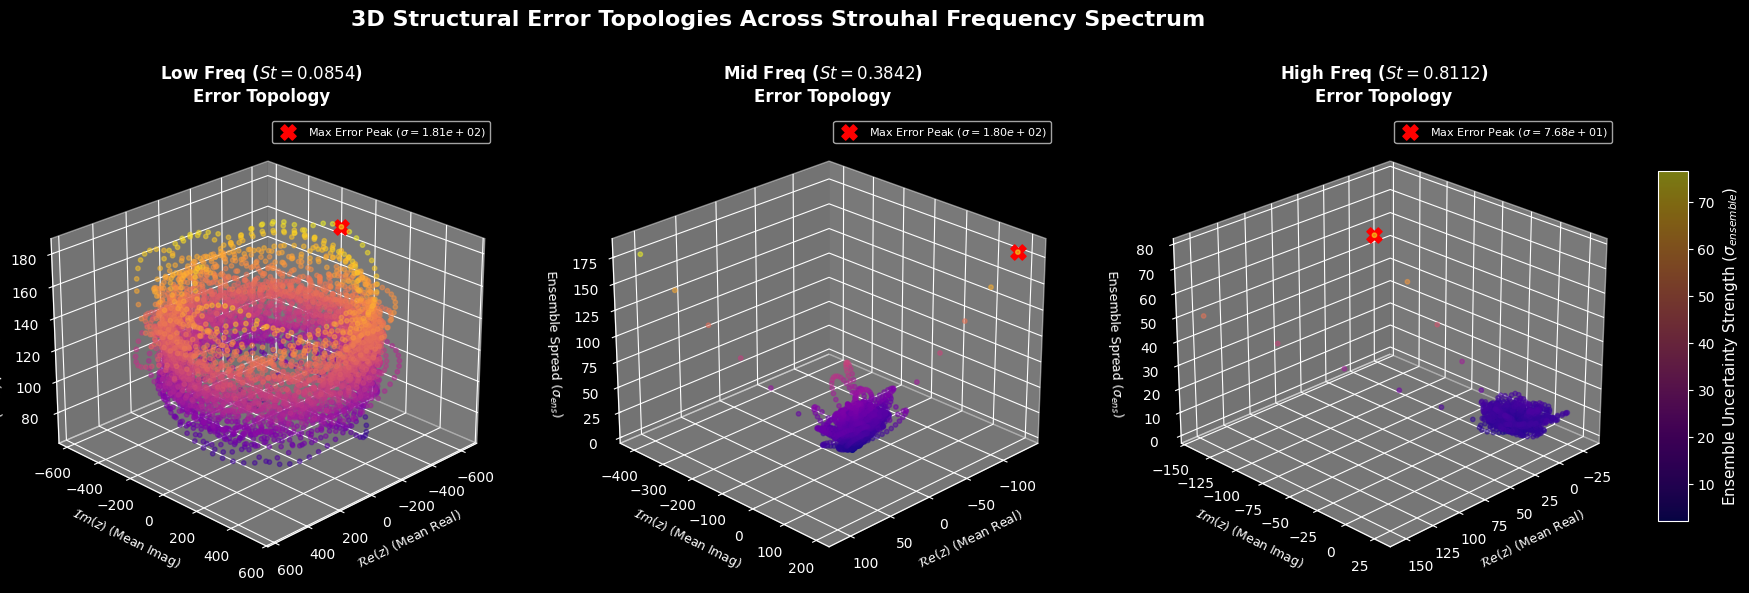

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# =====================================================================
# 1. LOAD THE ENTIRE MULTI-FREQUENCY DATASET
# =====================================================================
try:
    data = np.loadtxt('fno_sindy_ensemble_summary.txt', skiprows=1)
except FileNotFoundError:
    raise FileNotFoundError("Could not find 'fno_sindy_ensemble_summary.txt'. Please check your working directory.")

t = data[:, 0]
print(f"--- Data Processing Summary ---")
print(f"Total rows loaded: {len(t)}")

# Define frequency specific descriptors for labels
freqs_info = [
    {"label": "Low Freq ($St=0.0854$)", "col_start": 1},
    {"label": "Mid Freq ($St=0.3842$)", "col_start": 8},
    {"label": "High Freq ($St=0.8112$)", "col_start": 15}
]

# Set up a wide 3-panel figure to showcase the different frequency topologies
fig = plt.figure(figsize=(20, 7))

for idx, f_info in enumerate(freqs_info):
    start = f_info["col_start"]
    
    # Extract the distinct multi-variable columns mapped in the summary exporter
    true_real = data[:, start]
    true_imag = data[:, start + 1]
    mean_real = data[:, start + 2]
    mean_imag = data[:, start + 3]
    std_data  = data[:, start + 4] # Envelope Uncertainty Spread (Amplitude std)
    pure_real = data[:, start + 5]
    pure_imag = data[:, start + 6]

    # Find the independent uncertainty peak index for this frequency branch
    max_v_idx = np.argmax(std_data)
    
    print(f"\n[{f_info['label']}]")
    print(f"  Highest Variance Peak found at index: {max_v_idx}")
    print(f"  Ensemble Uncertainty Spread at peak:  {std_data[max_v_idx]:.4e}")

    # Create 3D Subplot for the current frequency branch
    ax = fig.add_subplot(131 + idx, projection='3d')
    
    # Scatter phase-space trajectory
    surf = ax.scatter(mean_real, mean_imag, std_data, 
                      c=std_data, cmap='plasma', s=10, alpha=0.5)
    
    # Plot the specific critical error peak on the manifold
    ax.scatter(mean_real[max_v_idx], mean_imag[max_v_idx], std_data[max_v_idx],
               color='red', marker='X', s=120, depthshade=False, 
               label=f'Max Error Peak ($\sigma = {std_data[max_v_idx]:.2e}$)')
    
    # Labels and font adjustments per panel
    ax.set_title(f'{f_info["label"]}\nError Topology', fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('$\mathcal{R}e(z)$ (Mean Real)', fontsize=9, labelpad=5)
    ax.set_ylabel('$\mathcal{I}m(z)$ (Mean Imag)', fontsize=9, labelpad=5)
    ax.set_zlabel('Ensemble Spread ($\sigma_{ens}$)', fontsize=9, labelpad=5)
    
    ax.legend(loc='upper right', fontsize=8, frameon=True)
    ax.view_init(elev=25, azim=45)

# Add a collective colorbar for visual clarity
fig.subplots_adjust(right=0.92)
cbar_ax = fig.add_axes([0.94, 0.25, 0.015, 0.5])
cbar = fig.colorbar(surf, cbar_ax)
cbar.set_label('Ensemble Uncertainty Strength ($\sigma_{ensemble}$)', fontsize=11)

plt.suptitle('3D Structural Error Topologies Across Strouhal Frequency Spectrum', 
             fontsize=16, fontweight='bold', y=0.98)

plt.savefig('multi_frequency_error_manifold_3d.png', dpi=300, bbox_inches='tight')
plt.show()

[INFO] Loading database spatial modes...
[INFO] Loading FNO ensemble coefficients...
[INFO] Computing global color scale...
[INFO] Rendering and saving to disk: 'dark_pressure_reconstruction.mp4'...
[INFO]   rendered frame 169/5248

CalledProcessError: Command '['ffmpeg', '-f', 'rawvideo', '-vcodec', 'rawvideo', '-s', '1600x1000', '-pix_fmt', 'rgba', '-framerate', '15', '-loglevel', 'error', '-i', 'pipe:', '-vcodec', 'h264', '-pix_fmt', 'yuv420p', '-y', 'dark_pressure_reconstruction.mp4']' returned non-zero exit status 255.

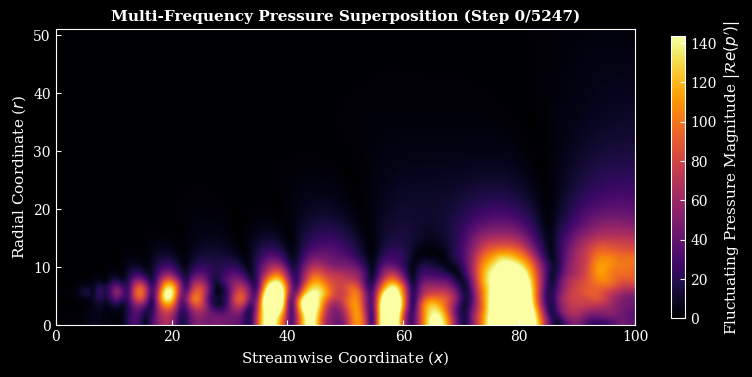

In [ ]:
import numpy as np
import h5py as h
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# =====================================================================
# 1. LOAD SPATIAL MODES FROM MASTER DATABASE
# =====================================================================
data_path = '/Users/icarus/Desktop/SPODcode/spod_matlab/spod_complete_continuous_database.mat'

print("[INFO] Loading database spatial modes...")
with h.File(data_path, 'r') as file:
    st_vector = np.squeeze(file['St_vector'][:])
    target_st_list = [0.1, 0.4, 0.8]
    mode_idx = 0
    psi_spatial_modes = []
    for target_st in target_st_list:
        target_fi = int(np.argmin(np.abs(st_vector - target_st)))
        psi_grid_raw = file['P'][mode_idx, :, :, target_fi]
        psi_spatial_modes.append(psi_grid_raw['real'] + 1j * psi_grid_raw['imag'])

nx_grid, nr_grid = psi_spatial_modes[0].shape

# =====================================================================
# 2. READ THE RAW ENSEMBLE PREDICTIONS
# =====================================================================
print("[INFO] Loading FNO ensemble coefficients...")
ensemble_coefs = np.load('fno_ensemble_coefficients.npy')
num_realizations, num_freqs, pred_len = ensemble_coefs.shape

j_realization = 0
z_preds = ensemble_coefs[j_realization, :, :]  # Shape: [3, pred_len]

def reconstruct_field(frame_idx):
    """Your original, mathematically correct linear superposition."""
    field = np.zeros((nr_grid, nx_grid), dtype=np.complex64)
    for ch in range(3):
        field += z_preds[ch, frame_idx] * psi_spatial_modes[ch].T
    
    # Absolute value of the real part forces both positive and negative 
    # wave lobes to glow intensely while ambient zero zones drop to total black
    return np.abs(field.real)

print("[INFO] Computing global color scale...")
frame_abs_p99 = np.empty(pred_len)
for f in range(pred_len):
    frame_abs_p99[f] = np.percentile(reconstruct_field(f), 99)

abs_max = np.percentile(frame_abs_p99, 95)  
vmin, vmax = 0, abs_max  

# 'inferno' maps zero to pitch black, and goes to glowing orange/white at the wave peaks
field_cmap = 'inferno'

# =====================================================================
# 3. RENDER AND SAVE THE PURE TRAVELING WAVE VISUALIZATION
# =====================================================================
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(8, 5))

init_field = reconstruct_field(0)

im = ax.imshow(init_field, cmap=field_cmap, origin='lower',
                extent=[0, nx_grid, 0, nr_grid],
                vmin=vmin, vmax=vmax, interpolation='bicubic')

ax.set_xlabel("Streamwise Coordinate ($x$)", color='white')
ax.set_ylabel("Radial Coordinate ($r$)", color='white')

cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.05)
cbar.set_label(r"Fluctuating Pressure Magnitude $|\mathcal{R}e(p')|$", color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

title = ax.set_title(f"Multi-Frequency Pressure Superposition (Step 0/{pred_len - 1})",
                      fontsize=11, fontweight='bold', color='white')

plt.tight_layout()

def update_frame(frame_idx):
    im.set_array(reconstruct_field(frame_idx))
    title.set_text(f"Multi-Frequency Pressure Superposition (Step {frame_idx}/{pred_len - 1})")
    return [im, title]

ani = animation.FuncAnimation(fig, update_frame, frames=pred_len, interval=60, blit=False)

output_filename = 'dark_pressure_reconstruction.mp4'
print(f"[INFO] Rendering and saving to disk: '{output_filename}'...")

def report_progress(current_frame, total_frames):
    print(f"\r[INFO]   rendered frame {current_frame + 1}/{total_frames}", end="", flush=True)

ani.save(output_filename, writer='ffmpeg', fps=15, dpi=200, progress_callback=report_progress)
print()  

print(f"[SUCCESS] Pristine high-contrast traveling wave animation saved to {output_filename}!")
plt.close(fig)